<div dir="rtl">

### توقّع وقت توصيل الطلبات

- **المشكلة المختارة:** المشكلة 3، التشغيل: متى يصل طلبي؟
- **سبب الاختيار:** اخترت هذه المشكلة لانها قريبة من تجربتي اليومية كمستخدمة لتطبيقات التوصيل، ولفت انتباهي كيف ممكن البيانات تتنبأ بوقت وصول الطلب بدقة وتحسن تجربة العميل
- **الداتا:** `Food Delivery Dataset`، 45,593 طلب و20 عمود
- **الـ Target:** `Time_taken(min)` (وقت التوصيل بالدقائق)
- **الريبو:** https://github.com/Manar-Mohammed8/delivery-time-prediction

</div>

<div dir="rtl">

## 1. فهم المشكلة

**1. من العميل؟ وكم تكلفه المشكلة؟**
العميل هو شركة أو تطبيق توصيل طعام عنده أكثر من 45 ألف طلب في البيانات. المشكلة أن وقت التوصيل يتراوح بين 10 و54 دقيقة، وهذا يعني فيه فرق كبير بين أسرع وأبطأ طلب. ولما يتأخر الطلب عن الوقت المتوقع ممكن يعطي الزبون تقييم سلبي ويخسر التطبيق بعض الزباين

**2. ايش الـ Target ونوعه؟**
الـ Target هو `Time_taken(min)` ويمثل وقت التوصيل بالدقائق. نوعه رقمي مستمر (`Continuous Numerical Value`)، لذلك تعتبر هذه المشكلة من نوع `Regression` لان الهدف هو التنبؤ بقيمة رقمية

**3. من يستخدم المنتج؟ وايش يحتاج يشوف؟**
يستخدم المنتج الزبون الي ينتظر طلبه، وكمان يقدر يستخدمه مدير التشغيل في شركة التوصيل. الزبون يحتاج يعرف وقت وصول الطلب المتوقع بشكل أدق، بينما مدير التشغيل يحتاج يتابع العوامل الي تأثر على التأخير ويحسن كفاءة عمليات التوصيل

**3 أسئلة فرعية:**
1. ايش تأثير حالة الطقس على وقت التوصيل؟
2. هل المسافة بين المطعم وموقع التوصيل تأثر على مدة التوصيل؟
3. ايش تأثير الازدحام المروري على وقت التوصيل؟

</div>

<div dir="rtl">

## 2. أول نظرة

</div>

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("data/raw.csv")
df.shape

(45593, 20)

In [2]:
df.head()

,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,Time_Order_picked,Weatherconditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken(min)
0,0x4607,INDORES13DEL02,37,4.9,22.745049,75.892471,22.765049,75.912471,19-03-2022,11:30:00,11:45:00,conditions Sunny,High,2,Snack,motorcycle,0,No,Urban,(min) 24
1,0xb379,BANGRES18DEL02,34,4.5,12.913041,77.683237,13.043041,77.813237,25-03-2022,19:45:00,19:50:00,conditions Stormy,Jam,2,Snack,scooter,1,No,Metropolitian,(min) 33
2,0x5d6d,BANGRES19DEL01,23,4.4,12.914264,77.678400,12.924264,77.688400,19-03-2022,08:30:00,08:45:00,conditions Sandstorms,Low,0,Drinks,motorcycle,1,No,Urban,(min) 26
3,0x7a6a,COIMBRES13DEL02,38,4.7,11.003669,76.976494,11.053669,77.026494,05-04-2022,18:00:00,18:10:00,conditions Sunny,Medium,0,Buffet,motorcycle,1,No,Metropolitian,(min) 21
4,0x70a2,CHENRES12DEL01,32,4.6,12.972793,80.249982,13.012793,80.289982,26-03-2022,13:30:00,13:45:00,conditions Cloudy,High,1,Snack,scooter,1,No,Metropolitian,(min) 30


In [3]:
df.columns.tolist()

['ID',
 'Delivery_person_ID',
 'Delivery_person_Age',
 'Delivery_person_Ratings',
 'Restaurant_latitude',
 'Restaurant_longitude',
 'Delivery_location_latitude',
 'Delivery_location_longitude',
 'Order_Date',
 'Time_Orderd',
 'Time_Order_picked',
 'Weatherconditions',
 'Road_traffic_density',
 'Vehicle_condition',
 'Type_of_order',
 'Type_of_vehicle',
 'multiple_deliveries',
 'Festival',
 'City',
 'Time_taken(min)']

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45593 entries, 0 to 45592
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID                           45593 non-null  object 
 1   Delivery_person_ID           45593 non-null  object 
 2   Delivery_person_Age          45593 non-null  object 
 3   Delivery_person_Ratings      45593 non-null  object 
 4   Restaurant_latitude          45593 non-null  float64
 5   Restaurant_longitude         45593 non-null  float64
 6   Delivery_location_latitude   45593 non-null  float64
 7   Delivery_location_longitude  45593 non-null  float64
 8   Order_Date                   45593 non-null  object 
 9   Time_Orderd                  45593 non-null  object 
 10  Time_Order_picked            45593 non-null  object 
 11  Weatherconditions            45593 non-null  object 
 12  Road_traffic_density         45593 non-null  object 
 13  Vehicle_conditio

In [5]:
df.isna().sum()

ID                             0
Delivery_person_ID             0
Delivery_person_Age            0
Delivery_person_Ratings        0
Restaurant_latitude            0
Restaurant_longitude           0
Delivery_location_latitude     0
Delivery_location_longitude    0
Order_Date                     0
Time_Orderd                    0
Time_Order_picked              0
Weatherconditions              0
Road_traffic_density           0
Vehicle_condition              0
Type_of_order                  0
Type_of_vehicle                0
multiple_deliveries            0
Festival                       0
City                           0
Time_taken(min)                0
dtype: int64

In [6]:
df.duplicated().sum()

0

In [7]:
df.describe()

,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Vehicle_condition
count,45593.000000,45593.000000,45593.000000,45593.000000,45593.000000
mean,17.017729,70.231332,17.465186,70.845702,1.023359
std,8.185109,22.883647,7.335122,21.118812,0.839065
min,-30.905562,-88.366217,0.010000,0.010000,0.000000
25%,12.933284,73.170000,12.988453,73.280000,0.000000
50%,18.546947,75.898497,18.633934,76.002574,1.000000
75%,22.728163,78.044095,22.785049,78.107044,2.000000
max,30.914057,88.433452,31.054057,88.563452,3.000000


In [8]:
text_cols = df.select_dtypes(include="object").columns
for col in text_cols:
    print(col, df[col].nunique())
    print(df[col].unique()[:10])
    print()

ID 45593
['0x4607 ' '0xb379 ' '0x5d6d ' '0x7a6a ' '0x70a2 ' '0x9bb4 ' '0x95b4 '
 '0x9eb2 ' '0x1102 ' '0xcdcd ']

Delivery_person_ID 1320
['INDORES13DEL02 ' 'BANGRES18DEL02 ' 'BANGRES19DEL01 ' 'COIMBRES13DEL02 '
 'CHENRES12DEL01 ' 'HYDRES09DEL03 ' 'RANCHIRES15DEL01 ' 'MYSRES15DEL02 '
 'HYDRES05DEL02 ' 'DEHRES17DEL01 ']

Delivery_person_Age 23
['37' '34' '23' '38' '32' '22' '33' '35' '36' '21']

Delivery_person_Ratings 29
['4.9' '4.5' '4.4' '4.7' '4.6' '4.8' '4.2' '4.3' '4' '4.1']

Order_Date 44
['19-03-2022' '25-03-2022' '05-04-2022' '26-03-2022' '11-03-2022'
 '04-03-2022' '14-03-2022' '20-03-2022' '12-02-2022' '13-02-2022']

Time_Orderd 177
['11:30:00' '19:45:00' '08:30:00' '18:00:00' '13:30:00' '21:20:00'
 '19:15:00' '17:25:00' '20:55:00' '21:55:00']

Time_Order_picked 193
['11:45:00' '19:50:00' '08:45:00' '18:10:00' '13:45:00' '21:30:00'
 '19:30:00' '17:30:00' '21:05:00' '22:10:00']

Weatherconditions 7
['conditions Sunny' 'conditions Stormy' 'conditions Sandstorms'
 'conditions Clou

<div dir="rtl">

## 3. مفاجآت الداتا

</div>

In [9]:
for col in df.select_dtypes(include="object").columns:
    n = df[col].astype(str).str.strip().isin(["NaN", "conditions NaN"]).sum()
    if n > 0:
        print(col, n)

Delivery_person_Age 1854
Delivery_person_Ratings 1908
Time_Orderd 1731
Weatherconditions 616
Road_traffic_density 601
multiple_deliveries 993
Festival 228
City 1200


In [10]:
for col in df.select_dtypes(include="object").columns:
    n = (df[col] != df[col].str.strip()).sum()
    if n > 0:
        print(col, n)

ID 45593
Delivery_person_ID 45593
Delivery_person_Age 1854
Delivery_person_Ratings 1908
Time_Orderd 1731
Road_traffic_density 45593
Type_of_order 45593
Type_of_vehicle 45593
multiple_deliveries 993
Festival 45593
City 45593


In [11]:
print("Restaurant_latitude == 0:", (df["Restaurant_latitude"] == 0).sum())
print("Restaurant_latitude < 0:", (df["Restaurant_latitude"] < 0).sum())
print("Restaurant_longitude == 0:", (df["Restaurant_longitude"] == 0).sum())
print("Restaurant_longitude < 0:", (df["Restaurant_longitude"] < 0).sum())
print("Delivery_location_latitude <= 1:", (df["Delivery_location_latitude"] <= 1).sum())
print("Delivery_location_longitude <= 1:", (df["Delivery_location_longitude"] <= 1).sum())
print("Delivery (lat و lon معا) <= 1:",
      ((df["Delivery_location_latitude"] <= 1) & (df["Delivery_location_longitude"] <= 1)).sum())

Restaurant_latitude == 0: 3640
Restaurant_latitude < 0: 431
Restaurant_longitude == 0: 3640
Restaurant_longitude < 0: 162
Delivery_location_latitude <= 1: 3640
Delivery_location_longitude <= 1: 3640
Delivery (lat و lon معا) <= 1: 3640


In [12]:
neg = df[df["Restaurant_latitude"] < 0]["Restaurant_latitude"]
neg.abs().describe()

count    431.000000
mean      20.302254
std        5.931208
min        9.959778
25%       15.497383
50%       21.170096
75%       24.430393
max       30.905562
Name: Restaurant_latitude, dtype: float64

In [13]:
zero_rows = (
    (df["Restaurant_latitude"] == 0)
    & (df["Restaurant_longitude"] == 0)
    & (df["Delivery_location_latitude"] <= 1)
    & (df["Delivery_location_longitude"] <= 1)
)
print("Rows where all 4 coordinates are zero:", zero_rows.sum())
print("Rows with only restaurant lat == 0:", (df["Restaurant_latitude"] == 0).sum()) 

Rows where all 4 coordinates are zero: 3640
Rows with only restaurant lat == 0: 3640


In [14]:
neg = df[df["Restaurant_latitude"] < 0]
diff_neg = (neg["Restaurant_latitude"].abs() - neg["Delivery_location_latitude"]).abs()

normal = df[(df["Restaurant_latitude"] > 0) & (df["Delivery_location_latitude"] > 1)]
diff_normal = (normal["Restaurant_latitude"] - normal["Delivery_location_latitude"]).abs()

print("Negative rows (abs): median diff =", round(diff_neg.median(), 3))
print("Normal rows: median diff =", round(diff_normal.median(), 3))

Negative rows (abs): median diff = 0.06
Normal rows: median diff = 0.06


<div dir="rtl">

### ملاحظة على الإحداثيات

- **الملاحظة:** من الفحص تبين أن الإحداثيات الأربعة تكون صفراً أو قريبة من الصفر في نفس 3640 صف، وهذا يدل على أن موقع المطعم وموقع التوصيل مفقودان بالكامل في هذي الصفوف وليس هناك خطأ في عمود واحد فقط. وكمان لاحظت أن القيم السالبة في `Restaurant_latitude` تبدو ناتجة عن خطأ في الإشارة، لأن الفرق الوسيط بعد استخدام القيمة المطلقة كان 0.06، وهو نفس الفرق الوسيط تقريباً في الصفوف الطبيعية. وكذلك القيم السالبة في `Restaurant_longitude` (162 صف) صححتها بنفس الطريقة، وبعد القيمة المطلقة صارت أقل قيمة فيه 72.77 وهذي قيمة طبيعية. لذلك أرجح أن الأصفار تمثل بيانات مفقودة، بينما القيم السالبة يمكن تصحيحها باستخدام القيمة المطلقة

</div>

<div dir="rtl">

### سجل المشاكل والقرارات المبدئية

| المشكلة | العمود | كم صف | القرار المبدئي |
| :--- | :--- | :---: | :--- |
| العمر مخزن كنص بدل رقم | `Delivery_person_Age` | 45593 | تحويله إلى رقم |
| تقييم المندوب مخزن كنص بدل رقم | `Delivery_person_Ratings` | 45593 | تحويله إلى رقم |
| عدد التوصيلات مخزن كنص رغم أن قيمه رقمية | `multiple_deliveries` | 45593 | تحويله إلى رقم |
| وقت التوصيل يحتوي على (min) ومخزن كنص | `Time_taken(min)` | 45593 | إزالة (min) وتحويله إلى رقم |
| التاريخ مخزن كنص | `Order_Date` | 45593 | تحويله إلى نوع تاريخ |
| وقت الطلب مخزن كنص | `Time_Orderd` | 45593 | تحويله إلى نوع وقت |
| وقت استلام الطلب مخزن كنص | `Time_Order_picked` | 45593 | تحويله إلى نوع وقت |
| وجود كلمة زائدة conditions داخل قيم الطقس | `Weatherconditions` | 45593 | حذف النص الزائد والاحتفاظ بحالة الطقس فقط |
| قيم مفقودة مخفية على شكل NaN | `Delivery_person_Age` | 1854 | تحويلها إلى NaN حقيقي ثم معالجتها |
| قيم مفقودة مخفية على شكل NaN | `Delivery_person_Ratings` | 1908 | تحويلها إلى NaN حقيقي ثم معالجتها |
| قيم مفقودة مخفية على شكل NaN | `Time_Orderd` | 1731 | تحويلها إلى NaN حقيقي ثم معالجتها |
| قيم مفقودة مخفية على شكل NaN | `Weatherconditions` | 616 | تحويلها إلى NaN حقيقي ثم معالجتها |
| قيم مفقودة مخفية على شكل NaN | `Road_traffic_density` | 601 | تحويلها إلى NaN حقيقي ثم معالجتها |
| قيم مفقودة مخفية على شكل NaN | `multiple_deliveries` | 993 | تحويلها إلى NaN حقيقي ثم معالجتها |
| قيم مفقودة مخفية على شكل NaN | `Festival` | 228 | تحويلها إلى NaN حقيقي ثم معالجتها |
| قيم مفقودة مخفية على شكل NaN | `City` | 1200 | تحويلها إلى NaN حقيقي ثم معالجتها |
| مسافات زائدة في القيم النصية | `ID`, `Delivery_person_ID`, `Road_traffic_density`, `Type_of_order`, `Type_of_vehicle`, `Festival`, `City` | 45593 | استخدام `str.strip()` |
| إحداثيات غير منطقية | `Restaurant_latitude` | 4071 | راح أتعامل مع القيم الصفرية (3640 صف) كقيم مفقودة، أما القيم السالبة (431 صف) فراح أصححها باستخدام القيمة المطلقة |
| إحداثيات غير منطقية | `Restaurant_longitude` | 3802 | راح أتعامل مع القيم الصفرية (3640 صف) كقيم مفقودة، أما القيم السالبة (162 صف) فراح أصححها باستخدام القيمة المطلقة |
| إحداثيات غير منطقية | `Delivery_location_latitude` | 3640 | راح أتعامل مع القيم القريبة من الصفر كقيم مفقودة لأنها تظهر في نفس صفوف الإحداثيات المفقودة للمطعم |
| إحداثيات غير منطقية | `Delivery_location_longitude` | 3640 | راح أتعامل مع القيم القريبة من الصفر كقيم مفقودة لأنها تظهر في نفس صفوف الإحداثيات المفقودة للمطعم |

</div>


<div dir="rtl">

## 4. الاستكشاف البصري (`EDA`)

### الرسمة 1: توزيع وقت التوصيل (`Time_taken(min)`)

- **توقعي:** أتوقع أن أغلب أوقات التوصيل تكون بين 20 و40 دقيقة، وأن تكون أعلى كثافة للطلبات قرب 25 إلى 30 دقيقة، وكمان يقل عدد الطلبات كلما ابتعدنا عن هذي الفترة الزمنية

</div>

In [15]:
df_eda = df.copy()
df_eda["Time_taken(min)"] = (df_eda["Time_taken(min)"]
                             .str.replace("(min)", "", regex=False)
                             .astype(int))

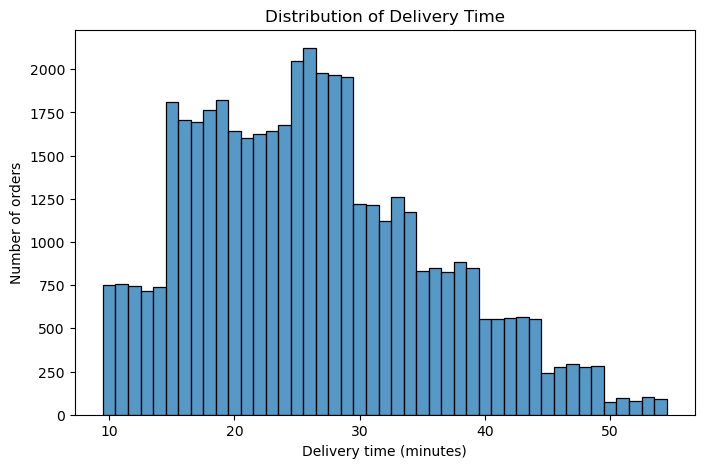

In [16]:
plt.figure(figsize=(8, 5))
sns.histplot(df_eda["Time_taken(min)"], discrete=True)
plt.title("Distribution of Delivery Time")
plt.xlabel("Delivery time (minutes)")
plt.ylabel("Number of orders")
plt.show()

In [17]:
print(df_eda["Time_taken(min)"].describe())

count    45593.000000
mean        26.294607
std          9.383806
min         10.000000
25%         19.000000
50%         26.000000
75%         32.000000
max         54.000000
Name: Time_taken(min), dtype: float64


In [18]:
print("Most frequent delivery time:", df_eda["Time_taken(min)"].mode()[0])

Most frequent delivery time: 26


<div dir="rtl">

- **الملاحظة:** بينت الرسمة أن أكثر وقت توصيل تكرر في البيانات هو 26 دقيقة، وهو قريب من توقعي السابق. وكمان المتوسط (26.3 دقيقة) والوسيط (26 دقيقة) متقاربين، وهذا يدل على أن أغلب الطلبات تخلص حول هذا الوقت. ولاحظت أن عدد الطلبات يبدأ ينزل بشكل واضح بعد 29 دقيقة تقريباً، وبعدين يصير نزول ثاني بعد 40 دقيقة. وبالمقابل لسه فيه عدد كويس من الطلبات توصل خلال 10 إلى 12 دقيقة. وكمان يبان أن التوزيع مو متماثل بسبب امتداده نحو أوقات التوصيل الأطول لحد 54 دقيقة. أقل وقت توصيل كان 10 دقائق وأعلى وقت كان 54 دقيقة، وما طلعت قيم سالبة أو مو منطقية
- **القرار:** راح أحتفظ بعمود `Time_taken(min)` زي ما هو بعد تحويله لرقم، لأن قيمه جاية ضمن نطاق منطقي وما طلعت فيه قيم تستدعي أحذف صفوف أو أسوي معالجة إضافية

</div>

<div dir="rtl">

### الرسمة 2: متوسط وقت التوصيل حسب حالة الطقس (`Weatherconditions`)

- **توقعي:** أتوقع أن يكون أعلى متوسط لوقت التوصيل في حالة `Stormy` أو `Sandstorms` ويكون قريب من 30 دقيقة. أما في الطقس `Sunny` فأتوقع أن يكون الأسرع بمتوسط يقارب 24 دقيقة. أتوقع أن يكون الفرق بين أسرع وأبطأ حالة طقس حوالي 5 إلى 7 دقائق

</div>

In [19]:
df_eda["Weatherconditions"] = (df_eda["Weatherconditions"]
                               .str.replace("conditions ", "", regex=False)
                               .str.strip())
df_eda["Weatherconditions"].value_counts()

Weatherconditions
Fog           7654
Stormy        7586
Cloudy        7536
Sandstorms    7495
Windy         7422
Sunny         7284
NaN            616
Name: count, dtype: int64

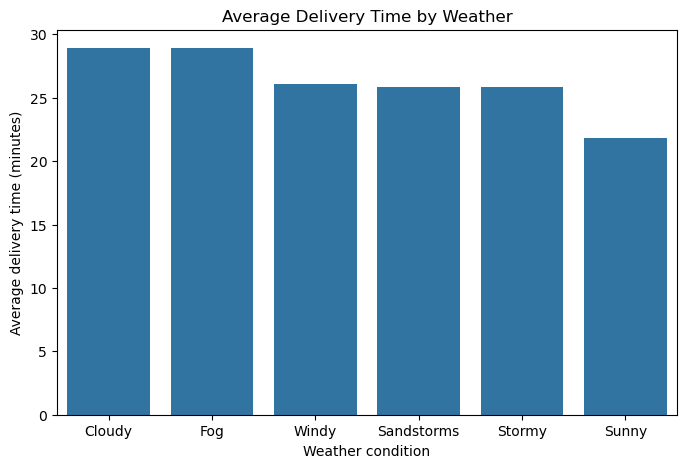

Weatherconditions
Cloudy        28.9
Fog           28.9
Windy         26.1
Sandstorms    25.9
Stormy        25.9
Sunny         21.9
Name: Time_taken(min), dtype: float64


In [20]:
order = (df_eda[df_eda["Weatherconditions"] != "NaN"]
         .groupby("Weatherconditions")["Time_taken(min)"]
         .mean()
         .sort_values(ascending=False))

plt.figure(figsize=(8, 5))
sns.barplot(x=order.index, y=order.values)
plt.title("Average Delivery Time by Weather")
plt.xlabel("Weather condition")
plt.ylabel("Average delivery time (minutes)")
plt.show()

print(order.round(1))

<div dir="rtl">

- **الملاحظة:** أظهرت الرسمة أن أعلى متوسط لوقت التوصيل كان في حالتي `Cloudy` و `Fog` بمتوسط 28.9 دقيقة لكل منهما، بينما كانت `Sunny` الأسرع بمتوسط 21.9 دقيقة، وهي أسرع من توقعي (24 دقيقة). الفرق بين أسرع وأبطأ حالة بلغ حوالي 7 دقائق، وهو قريب من توقعي. توقعت أن تكون `Stormy` و `Sandstorms` الأبطأ، لكن متوسط وقت التوصيل فيهما كان 25.9 دقيقة فقط، لذلك كانتا ضمن الحالات المتوسطة وليستا الأعلى. ولاحظت أن عدد الطلبات في كل حالة طقس متقارب (حوالي 7300 إلى 7650 طلب)، فواضح أن الفروق جاية من البيانات نفسها ومو بسبب قلة عدد الطلبات
- **القرار:** راح أحتفظ بمتغير الطقس في التحليل لأنه يظهر ارتباطاً باختلاف متوسط وقت التوصيل بين الحالات المختلفة، حيث بلغ الفرق بين أسرع وأبطأ حالة حوالي 7 دقائق

</div>

<div dir="rtl">

### الرسمة 3: متوسط وقت التوصيل حسب الازدحام المروري (`Road_traffic_density`)

- **توقعي:** أتوقع أن يكون أعلى متوسط لوقت التوصيل عند مستوى الازدحام `Jam` بمتوسط يقارب 31 دقيقة، وأن يكون أقل متوسط عند مستوى `Low` بحدود 22 دقيقة، والفرق بينهما يكون حوالي 9 دقائق

</div>

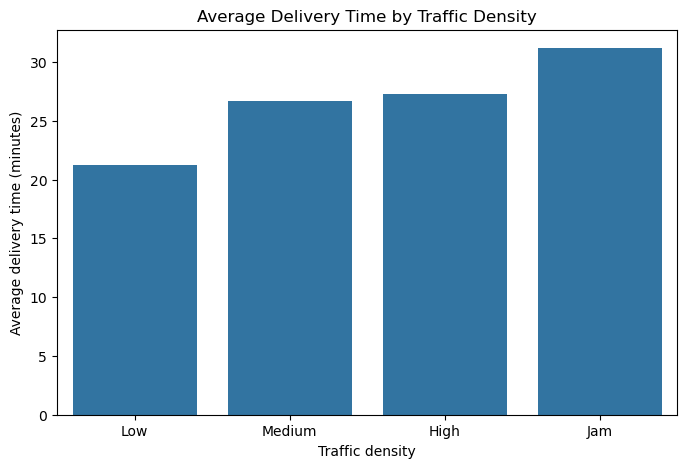

Road_traffic_density
Low       21.3
Medium    26.7
High      27.2
Jam       31.2
Name: Time_taken(min), dtype: float64


In [21]:
df_eda["Road_traffic_density"] = df_eda["Road_traffic_density"].str.strip()

traffic_order = ["Low", "Medium", "High", "Jam"]
avg_time = (df_eda[df_eda["Road_traffic_density"].isin(traffic_order)]
            .groupby("Road_traffic_density")["Time_taken(min)"]
            .mean()
            .reindex(traffic_order))

plt.figure(figsize=(8, 5))
sns.barplot(x=avg_time.index, y=avg_time.values)
plt.title("Average Delivery Time by Traffic Density")
plt.xlabel("Traffic density")
plt.ylabel("Average delivery time (minutes)")
plt.show()

print(avg_time.round(1))

<div dir="rtl">

- **الملاحظة:** أظهرت الرسمة أن متوسط وقت التوصيل يزيد مع زيادة الازدحام المروري، فكان الأعلى عند `Jam` بمتوسط 31.2 دقيقة والأقل عند `Low` بمتوسط 21.3 دقيقة، والفرق بينهما حوالي 9.9 دقيقة، وهو قريب من توقعي. وكمان لاحظت أن `Medium` (26.7 دقيقة) و`High` (27.2 دقيقة) متقاربان جداً، وأن الارتفاع الأكبر في وقت التوصيل ظهر عند `Jam`
- **القرار:** راح أحتفظ بعمود الازدحام المروري في التحليل لأنه يظهر ارتباطاً واضحاً بوقت التوصيل، حيث بلغ الفرق بين `Jam` و`Low` حوالي 10 دقائق

</div>

<div dir="rtl">

## 5. تنظيف الداتا

</div>

<div dir="rtl">

### 5.1 المسافات الزائدة والقيم المفقودة المخفية

</div>

In [22]:
import numpy as np

df_clean = df.copy()

# 1) إزالة المسافات الزائدة من كل الأعمدة النصية
for col in df_clean.select_dtypes(include="object").columns:
    df_clean[col] = df_clean[col].str.strip()

# 2) حذف كلمة conditions من قيم الطقس
df_clean["Weatherconditions"] = df_clean["Weatherconditions"].str.replace("conditions ", "", regex=False)

# 3) تحويل النص "NaN" إلى قيمة مفقودة حقيقية
df_clean = df_clean.replace("NaN", np.nan)

df_clean.isna().sum()

ID                                0
Delivery_person_ID                0
Delivery_person_Age            1854
Delivery_person_Ratings        1908
Restaurant_latitude               0
Restaurant_longitude              0
Delivery_location_latitude        0
Delivery_location_longitude       0
Order_Date                        0
Time_Orderd                    1731
Time_Order_picked                 0
Weatherconditions               616
Road_traffic_density            601
Vehicle_condition                 0
Type_of_order                     0
Type_of_vehicle                   0
multiple_deliveries             993
Festival                        228
City                           1200
Time_taken(min)                   0
dtype: int64

<div dir="rtl">

### 5.2 الأنواع والـ Target والإحداثيات

</div>

In [23]:
# الـ Target: إزالة (min) وتحويله لرقم
df_clean["Time_taken(min)"] = (df_clean["Time_taken(min)"]
                               .str.replace("(min)", "", regex=False)
                               .str.strip()
                               .astype(int))

# الأعمدة الرقمية المخزنة كنص (القيم المفقودة تبقى NaN)
for col in ["Delivery_person_Age", "Delivery_person_Ratings", "multiple_deliveries"]:
    df_clean[col] = pd.to_numeric(df_clean[col])

# الإحداثيات: السالب يتصحح بالقيمة المطلقة
df_clean["Restaurant_latitude"] = df_clean["Restaurant_latitude"].abs()
df_clean["Restaurant_longitude"] = df_clean["Restaurant_longitude"].abs()

# الأصفار تتحول إلى قيم مفقودة (نفس الصفوف في الأعمدة الأربعة)
coord_cols = ["Restaurant_latitude", "Restaurant_longitude",
              "Delivery_location_latitude", "Delivery_location_longitude"]
zero_rows = (df_clean["Restaurant_latitude"] == 0) & (df_clean["Restaurant_longitude"] == 0)
df_clean.loc[zero_rows, coord_cols] = np.nan

print(df_clean[coord_cols].isna().sum())
print(df_clean[coord_cols].describe().round(2))
df_clean.dtypes

Restaurant_latitude            3640
Restaurant_longitude           3640
Delivery_location_latitude     3640
Delivery_location_longitude    3640
dtype: int64
       Restaurant_latitude  Restaurant_longitude  Delivery_location_latitude  \
count             41953.00              41953.00                    41953.00   
mean                 18.91                 76.92                       18.98   
std                   5.47                  3.50                        5.47   
min                   9.96                 72.77                        9.97   
25%                  12.99                 73.90                       13.07   
50%                  19.07                 76.62                       19.12   
75%                  22.75                 78.37                       22.82   
max                  30.91                 88.43                       31.05   

       Delivery_location_longitude  
count                     41953.00  
mean                         76.99  
std        

ID                              object
Delivery_person_ID              object
Delivery_person_Age            float64
Delivery_person_Ratings        float64
Restaurant_latitude            float64
Restaurant_longitude           float64
Delivery_location_latitude     float64
Delivery_location_longitude    float64
Order_Date                      object
Time_Orderd                     object
Time_Order_picked               object
Weatherconditions               object
Road_traffic_density            object
Vehicle_condition                int64
Type_of_order                   object
Type_of_vehicle                 object
multiple_deliveries            float64
Festival                        object
City                            object
Time_taken(min)                  int32
dtype: object

<div dir="rtl">

- **النتيجة:** تم تحويل `Time_taken(min)` إلى نوع رقمي، وكمان تم تحويل `Delivery_person_Age` و`Delivery_person_Ratings` و`multiple_deliveries` إلى أرقام مع الإبقاء على القيم المفقودة. وفي أعمدة الإحداثيات تم تصحيح القيم السالبة باستخدام القيمة المطلقة وتحويل القيم الصفرية إلى قيم مفقودة، لذلك أصبح في كل عمود إحداثيات 3640 قيمة مفقودة. وكمان أصبحت أقل القيم موجبة وطبيعية، فمثلاً أقل قيمة في `Restaurant_latitude` أصبحت 9.96 بعد التنظيف

</div>

<div dir="rtl">

### 5.3 التاريخ والوقت

</div>

In [24]:
df_clean["Order_Date"] = pd.to_datetime(df_clean["Order_Date"], format="%d-%m-%Y")
df_clean["Time_Orderd"] = pd.to_datetime(df_clean["Time_Orderd"], format="%H:%M:%S")
df_clean["Time_Order_picked"] = pd.to_datetime(df_clean["Time_Order_picked"], format="%H:%M:%S")

print(df_clean[["Order_Date", "Time_Orderd", "Time_Order_picked"]].dtypes)
print(df_clean["Time_Orderd"].isna().sum())

Order_Date           datetime64[ns]
Time_Orderd          datetime64[ns]
Time_Order_picked    datetime64[ns]
dtype: object
1731


<div dir="rtl">

- **النتيجة:** تحولت `Order_Date` و`Time_Orderd` و`Time_Order_picked` إلى نوع تاريخ ووقت (`datetime64`)، وبقيت القيم المفقودة في `Time_Orderd` كما هي (1731 قيمة)

</div>

<div dir="rtl">

### 5.4 القيم المفقودة

</div>

In [25]:
missing = df_clean.isna().sum()
missing_pct = (df_clean.isna().mean() * 100).round(1)
print(pd.DataFrame({"missing": missing, "percent": missing_pct})[missing > 0])

                             missing  percent
Delivery_person_Age             1854      4.1
Delivery_person_Ratings         1908      4.2
Restaurant_latitude             3640      8.0
Restaurant_longitude            3640      8.0
Delivery_location_latitude      3640      8.0
Delivery_location_longitude     3640      8.0
Time_Orderd                     1731      3.8
Weatherconditions                616      1.4
Road_traffic_density             601      1.3
multiple_deliveries              993      2.2
Festival                         228      0.5
City                            1200      2.6


<div dir="rtl">

### جدول معالجة القيم المفقودة

| العمود | القيم المفقودة | النسبة | القرار |
| :--- | :---: | :---: | :--- |
| `Delivery_person_Age` | 1854 | 4.1% | راح أعوضها بالوسيط (`Median`) لأن العمود رقمي ونسبة الفقدان قليلة نسبياً |
| `Delivery_person_Ratings` | 1908 | 4.2% | راح أعوضها بالوسيط (`Median`) لنفس السبب |
| `multiple_deliveries` | 993 | 2.2% | راح أعوضها بالقيمة الأكثر تكراراً (`Mode`) لأن القيم فئوية (0، 1، 2، 3) |
| `Weatherconditions` | 616 | 1.4% | راح أستبدل القيم المفقودة بـ `Unknown` |
| `Road_traffic_density` | 601 | 1.3% | راح أستبدل القيم المفقودة بـ `Unknown` |
| `Festival` | 228 | 0.5% | راح أستبدل القيم المفقودة بـ `Unknown` |
| `City` | 1200 | 2.6% | راح أستبدل القيم المفقودة بـ `Unknown` |
| `Time_Orderd` | 1731 | 3.8% | راح أترك القيم المفقودة زي ما هي حالياً وأستخدم العمود عند الحاجة فقط |
| `Restaurant_latitude` | 3640 | 8.0% | ما راح أعوضها، وراح أستخدم الإحداثيات المتوفرة فقط لحساب المسافة |
| `Restaurant_longitude` | 3640 | 8.0% | ما راح أعوضها، وراح أستخدم الإحداثيات المتوفرة فقط لحساب المسافة |
| `Delivery_location_latitude` | 3640 | 8.0% | ما راح أعوضها، وراح أستخدم الإحداثيات المتوفرة فقط لحساب المسافة |
| `Delivery_location_longitude` | 3640 | 8.0% | ما راح أعوضها، وراح أستخدم الإحداثيات المتوفرة فقط لحساب المسافة |

</div>

In [26]:
# رقمية: الوسيط
df_clean["Delivery_person_Age"] = df_clean["Delivery_person_Age"].fillna(df_clean["Delivery_person_Age"].median())
df_clean["Delivery_person_Ratings"] = df_clean["Delivery_person_Ratings"].fillna(df_clean["Delivery_person_Ratings"].median())

# فئوية رقمية: الأكثر تكراراً
df_clean["multiple_deliveries"] = df_clean["multiple_deliveries"].fillna(df_clean["multiple_deliveries"].mode()[0])

# نصية: Unknown
for col in ["Weatherconditions", "Road_traffic_density", "Festival", "City"]:
    df_clean[col] = df_clean[col].fillna("Unknown")

remaining = df_clean.isna().sum()
print(remaining[remaining > 0])

Restaurant_latitude            3640
Restaurant_longitude           3640
Delivery_location_latitude     3640
Delivery_location_longitude    3640
Time_Orderd                    1731
dtype: int64


<div dir="rtl">

- **النتيجة:** بعد تنفيذ قرارات معالجة القيم المفقودة، ما بقى أي عمود فيه قيم مفقودة باستثناء أعمدة الإحداثيات الأربعة (`Restaurant_latitude`، `Restaurant_longitude`، `Delivery_location_latitude`، `Delivery_location_longitude`) الي فيها 3640 قيمة مفقودة في كل عمود، بالإضافة إلى `Time_Orderd` الي فيه 1731 قيمة مفقودة، وهذي الأعمدة الي تقرر الإبقاء على قيمها المفقودة زي ما هي في هذي المرحلة

</div>

<div dir="rtl">

### 5.5 فحص منطقية القيم

</div>

In [27]:
print(df_clean[["Delivery_person_Age", "Delivery_person_Ratings",
                "Vehicle_condition", "multiple_deliveries"]].describe().round(2))

print(df_clean["Delivery_person_Ratings"].value_counts().sort_index().tail(6))

       Delivery_person_Age  Delivery_person_Ratings  Vehicle_condition  \
count             45593.00                 45593.00           45593.00   
mean                 29.58                     4.64               1.02   
std                   5.70                     0.33               0.84   
min                  15.00                     1.00               0.00   
25%                  25.00                     4.60               0.00   
50%                  30.00                     4.70               1.00   
75%                  34.00                     4.80               2.00   
max                  50.00                     6.00               3.00   

       multiple_deliveries  
count             45593.00  
mean                  0.75  
std                   0.57  
min                   0.00  
25%                   0.00  
50%                   1.00  
75%                   1.00  
max                   3.00  
Delivery_person_Ratings
4.6    6940
4.7    9050
4.8    7148
4.9    7041


In [28]:
print("Ratings > 5:", (df_clean["Delivery_person_Ratings"] > 5).sum())
print("Ratings < 3:", (df_clean["Delivery_person_Ratings"] < 3).sum())
print("Age < 18:", (df_clean["Delivery_person_Age"] < 18).sum())
print(df_clean["Delivery_person_Age"].value_counts().sort_index().head(5))

Ratings > 5: 53
Ratings < 3: 140
Age < 18: 38
Delivery_person_Age
15.0      38
20.0    2136
21.0    2153
22.0    2196
23.0    2087
Name: count, dtype: int64


<div dir="rtl">

1. **التقييم 6.0 (53 صف):**
  - **القرار:** راح أحولها لقيم مفقودة وبعدين أعوضها بالوسيط (`Median`)
  - **السبب:** قيمة 6.0 خارج نطاق التقييم المتوقع (من 1 إلى 5)، عشان كذا تعتبر قيمة مو منطقية. وبما أن عددها قليل جداً (53 صف بس)، فالأفضل أعاملها كقيم مفقودة وأعوضها بالوسيط بدل ما أفترض أنها 5 أو أحذف الصفوف بالكامل

2. **العمر 15 (38 صف):**
  - **القرار:** راح أحولها لقيم مفقودة وبعدين أعوضها بالوسيط (`Median`)
  - **السبب:** كل القيم الأقل من 18 كانت 15 سنة بس، وما فيه أعمار 16 أو 17 أو 18 أو 19، بينما التوزيع الطبيعي يبدأ مباشرة من 20 سنة بأعداد كبيرة. هذا يخلي عمر 15 يبان منفصل عن باقي البيانات ويرجح أنه خطأ في الإدخال، عشان كذا راح أتعامل معاه كقيمة مو صحيحة وأعوضه بالوسيط

3. **التقييم أقل من 3 (140 صف):**
  - **القرار:** راح أتركها زي ما هي بدون تعديل
  - **السبب:** التقييمات الأقل من 3 عادية ومقبولة لأنها لسه ضمن نطاق التقييم الطبيعي (من 1 إلى 5). ورغم أنها قليلة مقارنة بباقي التقييمات، إلا أنها ممكن تمثل تقييمات منخفضة حقيقية لمندوبين قدموا خدمة مو مرضية، فما عندي دليل كافي يخليني أعتبرها أخطاء في البيانات أو أعدلها

</div>

In [29]:
# قيم غير منطقية تتحول إلى مفقودة
df_clean.loc[df_clean["Delivery_person_Ratings"] > 5, "Delivery_person_Ratings"] = np.nan
df_clean.loc[df_clean["Delivery_person_Age"] < 18, "Delivery_person_Age"] = np.nan

print("Missing ratings:", df_clean["Delivery_person_Ratings"].isna().sum())
print("Missing ages:", df_clean["Delivery_person_Age"].isna().sum())

# تعويضها بالوسيط (بعد استبعاد القيم غير المنطقية)
df_clean["Delivery_person_Ratings"] = df_clean["Delivery_person_Ratings"].fillna(df_clean["Delivery_person_Ratings"].median())
df_clean["Delivery_person_Age"] = df_clean["Delivery_person_Age"].fillna(df_clean["Delivery_person_Age"].median())

print("Max rating:", df_clean["Delivery_person_Ratings"].max())
print("Min age:", df_clean["Delivery_person_Age"].min())

Missing ratings: 53
Missing ages: 38
Max rating: 5.0
Min age: 20.0


<div dir="rtl">

- **النتيجة:** بعد تحويل التقييمات الأكبر من `5` (53 صف) والأعمار الأقل من `18` (38 صف) إلى قيم مفقودة وتعويضها بالوسيط (`Median`) المحسوب بعد استبعاد القيم غير المنطقية، صار أقصى تقييم ضمن النطاق الطبيعي وأقل عمر منطقي ومطابق لبقية البيانات

</div>

<div dir="rtl">

### 5.6 الفحص النهائي

</div>

In [30]:
print("Shape:", df_clean.shape)
print("Duplicated rows:", df_clean.duplicated().sum())
print("Duplicated IDs:", df_clean["ID"].duplicated().sum())

Shape: (45593, 20)
Duplicated rows: 0
Duplicated IDs: 0


<div dir="rtl">

- **النتيجة:** بقي عدد الصفوف كما هو (45593 صف و20 عمود) وما فيه صفوف مكررة ولا `ID` مكرر، وبقيت `raw.csv` كما هي بدون تعديل

</div>

<div dir="rtl">

## 6. حساب المسافة بين المطعم وموقع التوصيل

</div>

<div dir="rtl">

- **الميزة الجديدة (`Distance_km`):** الداتا ما فيها عمود جاهز للمسافة، فراح أحسبها من إحداثيات المطعم وموقع التوصيل باستخدام معادلة `Haversine` (المسافة على سطح الأرض بالكيلومتر). وللصفوف الي إحداثياتها مفقودة (3640 صف) تكون المسافة مفقودة كذلك، حسب قراري السابق بعدم التعويض

</div>

In [31]:
def haversine_km(lat1, lon1, lat2, lon2):
    R = 6371  # نصف قطر الأرض بالكيلومتر
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    return 2 * R * np.arcsin(np.sqrt(a))

df_clean["Distance_km"] = haversine_km(
    df_clean["Restaurant_latitude"], df_clean["Restaurant_longitude"],
    df_clean["Delivery_location_latitude"], df_clean["Delivery_location_longitude"]
)

print(df_clean["Distance_km"].isna().sum())
print(df_clean["Distance_km"].describe().round(2))

3640
count    41953.00
mean         9.72
std          5.60
min          1.47
25%          4.66
50%          9.19
75%         13.68
max         20.97
Name: Distance_km, dtype: float64


<div dir="rtl">

- **النتيجة:** حسبت المسافة لـ 41953 طلب، وبقيت مفقودة في 3640 صف (الصفوف الي إحداثياتها مفقودة). المسافة بين 1.47 و20.97 كم بمتوسط 9.72 كم ووسيط 9.19 كم
- **ملاحظة:** هذي مسافة مباشرة بين النقطتين (خط مستقيم) وليست مسافة الطريق الفعلية، فتقريبية

</div>

In [32]:
df_clean.to_csv("data/clean.csv", index=False)
print(df_clean.shape, "Distance_km" in df_clean.columns)

(45593, 21) True


<div dir="rtl">

- **النتيجة:** حفظت الداتا النظيفة في `data/clean.csv` بعد إضافة `Distance_km`، وصار الشكل (45593 صف و21 عمود)، وبقيت `raw.csv` كما هي بدون تعديل

</div>

<div dir="rtl">

### الرسمة 4: العلاقة بين المسافة ووقت التوصيل

- **توقعي:** أتوقع أن يزيد وقت التوصيل كلما زادت المسافة بين المطعم وموقع التوصيل، وأتوقع أن يكون متوسط وقت التوصيل للمسافات القصيرة (أقل من 5 كم) حوالي 22 إلى 25 دقيقة، بينما يكون متوسط وقت التوصيل للمسافات الطويلة (أكثر من 15 كم) حوالي 30 إلى 35 دقيقة. لذلك أتوقع أن يكون الفرق بين المجموعتين حوالي 8 إلى 10 دقائق

</div>

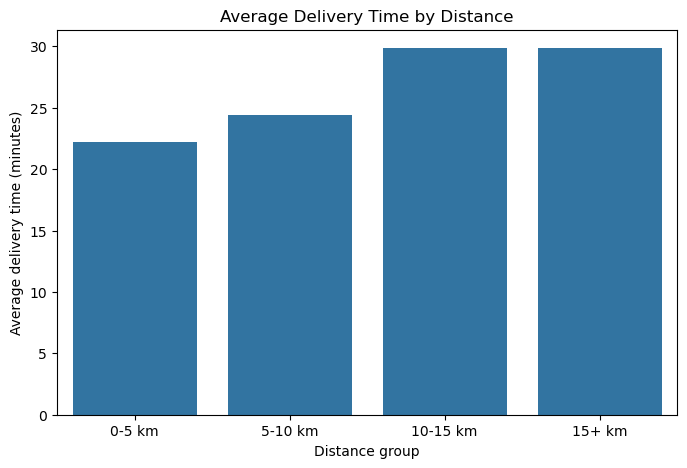

Distance_group
0-5 km      22.2
5-10 km     24.4
10-15 km    29.8
15+ km      29.9
Name: Time_taken(min), dtype: float64
Distance_group
0-5 km      11303
5-10 km     11307
10-15 km    11293
15+ km       8050
Name: count, dtype: int64


In [33]:
df_dist = df_clean.dropna(subset=["Distance_km"]).copy()

df_dist["Distance_group"] = pd.cut(
    df_dist["Distance_km"],
    bins=[0, 5, 10, 15, 25],
    labels=["0-5 km", "5-10 km", "10-15 km", "15+ km"]
)

avg_by_distance = df_dist.groupby("Distance_group", observed=True)["Time_taken(min)"].mean()
count_by_distance = df_dist["Distance_group"].value_counts().sort_index()

plt.figure(figsize=(8, 5))
sns.barplot(x=avg_by_distance.index, y=avg_by_distance.values)
plt.title("Average Delivery Time by Distance")
plt.xlabel("Distance group")
plt.ylabel("Average delivery time (minutes)")
plt.show()

print(avg_by_distance.round(1))
print(count_by_distance)

<div dir="rtl">

- **الملاحظة:** طلع فعلاً وقت التوصيل يزيد مع المسافة، فصار متوسطه 22.2 دقيقة للمسافات من 0 إلى 5 كم، و29.9 دقيقة للي أكثر من 15 كم، والفرق بينهم تقريباً 7.7 دقيقة وهو أقل شوي من توقعي (8 إلى 10 دقائق)، وكان متوسط أكثر من 15 كم (29.9) تحت توقعي (30 إلى 35) بفرق بسيط. بس لاحظت أن الزيادة مو مستمرة طول الوقت؛ ارتفع المتوسط بشكل واضح عند فئة 10 إلى 15 كم (29.8 دقيقة)، وبعدين ثبت تقريباً عند أكثر من 15 كم (29.9 دقيقة)
- **القرار:** راح أخلي عمود `Distance_km` معاي في التحليل لأنه واضح ارتباطه بوقت التوصيل، بس أحط في بالي أن المسافة هنا خط مستقيم بين نقطتين مو مسافة الطريق الفعلية

</div>

<div dir="rtl">

## 7. تجهيز الداتا للموديل

</div>

In [34]:
df_model = df_clean.copy()

# معلومات من التاريخ والوقت
df_model["Order_hour"] = df_model["Time_Orderd"].dt.hour
df_model["Order_dayofweek"] = df_model["Order_Date"].dt.dayofweek

print(df_model[["Order_hour", "Order_dayofweek"]].describe().round(2))
print(df_model["Order_hour"].isna().sum())

       Order_hour  Order_dayofweek
count    43862.00         45593.00
mean        17.42             3.00
std          4.82             1.97
min          0.00             0.00
25%         15.00             1.00
50%         19.00             3.00
75%         21.00             5.00
max         23.00             6.00
1731


<div dir="rtl">

- **النتيجة:** استخرجت `Order_hour` (ساعة الطلب، من 0 إلى 23) من `Time_Orderd`، و`Order_dayofweek` (يوم الأسبوع، من 0 إلى 6) من `Order_Date`. ساعة الطلب فيها 1731 قيمة مفقودة (نفس مفقودات `Time_Orderd`)، ومتوسطها 17.4 ووسيطها 19، يعني أغلب الطلبات تكون في المساء

</div>

<div dir="rtl">

- **القرار:** ما راح أستخدم `Time_Order_picked` في النموذج، لأن الهدف هو توقع وقت التوصيل في اللحظة الي يطلب فيها الزبون الطلب. في هذي اللحظة يكون وقت استلام الطلب من المطعم مو معروف لسه، فاستخدامه بيعطي النموذج معلومة مستقبلية ما تكون متاحة وقت التنبؤ
- **أعمدة أخرى راح أحذفها:** `ID` و`Delivery_person_ID` (أرقام تعريف بس)، و`Order_Date` و`Time_Orderd` (بعد ما استخرجت منهم اليوم والساعة)، والإحداثيات الأربعة (لأن `Distance_km` أخذت منها المعلومة)

</div>

In [35]:
drop_cols = ["ID", "Delivery_person_ID", "Order_Date", "Time_Orderd", "Time_Order_picked",
             "Restaurant_latitude", "Restaurant_longitude",
             "Delivery_location_latitude", "Delivery_location_longitude"]
df_model = df_model.drop(columns=drop_cols)

# ترميز الأعمدة النصية إلى 0/1
cat_cols = ["Weatherconditions", "Road_traffic_density", "Type_of_order",
            "Type_of_vehicle", "Festival", "City"]
df_model = pd.get_dummies(df_model, columns=cat_cols, dtype=int)

print("Shape:", df_model.shape)
print(df_model.columns.tolist())

remaining = df_model.isna().sum()
print(remaining[remaining > 0])

df_model.to_csv("data/model_ready.csv", index=False)
print("Saved: data/model_ready.csv")

Shape: (45593, 35)
['Delivery_person_Age', 'Delivery_person_Ratings', 'Vehicle_condition', 'multiple_deliveries', 'Time_taken(min)', 'Distance_km', 'Order_hour', 'Order_dayofweek', 'Weatherconditions_Cloudy', 'Weatherconditions_Fog', 'Weatherconditions_Sandstorms', 'Weatherconditions_Stormy', 'Weatherconditions_Sunny', 'Weatherconditions_Unknown', 'Weatherconditions_Windy', 'Road_traffic_density_High', 'Road_traffic_density_Jam', 'Road_traffic_density_Low', 'Road_traffic_density_Medium', 'Road_traffic_density_Unknown', 'Type_of_order_Buffet', 'Type_of_order_Drinks', 'Type_of_order_Meal', 'Type_of_order_Snack', 'Type_of_vehicle_bicycle', 'Type_of_vehicle_electric_scooter', 'Type_of_vehicle_motorcycle', 'Type_of_vehicle_scooter', 'Festival_No', 'Festival_Unknown', 'Festival_Yes', 'City_Metropolitian', 'City_Semi-Urban', 'City_Unknown', 'City_Urban']
Distance_km    3640
Order_hour     1731
dtype: int64
Saved: data/model_ready.csv


<div dir="rtl">

- **النتيجة:** جهزت الداتا للموديل: حذفت أعمدة التعريف والتاريخ والوقت الأصلية، وحذفت الإحداثيات الأربعة لأن `Distance_km` أخذت منها المعلومة، ورمزت الأعمدة النصية إلى أعمدة 0/1. صار الشكل النهائي (45593 صف و35 عمود)، وبقيت قيم مفقودة فقط في `Distance_km` (3640) و`Order_hour` (1731) وسأتعامل معهما عند تدريب النموذج
- **الملف:** `data/model_ready.csv`

</div>

<div dir="rtl">

## 8. فكرة المنتج

- **القرار:** راح أبني تطبيق يعتمد على البيانات التاريخية بدل نموذج تعلم آلة، لأنه أسهل أشرحه ومبني مباشرة على التحليل والاستكشاف الي سويته في البيانات
- **كيف يشتغل:** يختار الزبون أو المستخدم حالة الطقس ومستوى الازدحام والمسافة التقريبية، ثم يبحث التطبيق عن الطلبات المشابهة في البيانات ويعرض متوسط وقت التوصيل ونطاق تقريبي للوقت

</div>

In [36]:
example = df_clean[
    (df_clean["Weatherconditions"] == "Sunny")
    & (df_clean["Road_traffic_density"] == "Low")
    & (df_clean["Distance_km"] <= 5)
]["Time_taken(min)"]

print("Orders:", len(example))
print("Average:", round(example.mean(), 1))
print("Typical range (25%-75%):", example.quantile(0.25), "to", example.quantile(0.75))

Orders: 1095
Average: 17.8
Typical range (25%-75%): 14.0 to 21.0


<div dir="rtl">

- **مثال:** لو اختار المستخدم الطقس `Sunny` والازدحام `Low` والمسافة أقل من 5 كم، يبحث التطبيق عن الطلبات المشابهة في البيانات. في هذي الحالة لقى 1095 طلب مشابه، وكان متوسط وقت التوصيل 17.8 دقيقة، بينما وصلت 50% من الطلبات تقريباً خلال فترة تتراوح بين 14 و21 دقيقة. لذلك بتكون النتيجة المعروضة للمستخدم: "غالباً يصل طلبك خلال 14 إلى 21 دقيقة"
- **ملاحظة:** كل ما كثرت الشروط في البحث يقل عدد الطلبات المشابهة. ولازم التطبيق ينتبه إذا طلعت طلبات قليلة جدا (مثلاً أقل من 30 طلب)، لأن الرقم وقتها ما يكون مضمون وموثوق كفاية

</div>


In [37]:
def estimate_delivery_time(weather, traffic, distance_group, min_orders=30):
    bins = {"0-5 km": (0, 5), "5-10 km": (5, 10), "10-15 km": (10, 15), "15+ km": (15, 25)}
    low_km, high_km = bins[distance_group]

    similar = df_clean[
        (df_clean["Weatherconditions"] == weather)
        & (df_clean["Road_traffic_density"] == traffic)
        & (df_clean["Distance_km"] > low_km)
        & (df_clean["Distance_km"] <= high_km)
    ]["Time_taken(min)"]

    if len(similar) < min_orders:
        return None

    return {
        "orders": len(similar),
        "average": round(similar.mean(), 1),
        "low": similar.quantile(0.25),
        "high": similar.quantile(0.75),
    }

print(estimate_delivery_time("Sunny", "Low", "0-5 km"))
print(estimate_delivery_time("Fog", "Jam", "15+ km"))

{'orders': 1095, 'average': 17.8, 'low': 14.0, 'high': 21.0}
{'orders': 593, 'average': 41.4, 'low': 37.0, 'high': 45.0}


<div dir="rtl">

- **النتيجة:** ضبطت الدالة وطلعت نفس النتيجة الي جت في المثال السابق. لما اخترت `Sunny` و`Low` ومسافة `0-5 km` لقت 1095 طلب مشابه، وكان متوسط وقت التوصيل 17.8 دقيقة، ووصلت 50% من الطلبات تقريباً بين 14 و21 دقيقة. وفي الحالة الثانية (`Fog` مع `Jam` ومسافة `15+ km`) لقت الدالة 593 طلب مشابه، وارتفع متوسط وقت التوصيل لـ 41.4 دقيقة، والوقت المعتاد صار بين 37 و45 دقيقة، يعني واضح أن الضباب والزحمة الشديدة والمسافات الطويلة ترفع وقت التوصيل. وكمان حطيت شرط أن الدالة ترجع `None` إذا صار عدد الطلبات المشابهة أقل من 30 طلب، عشان ما أعطي تقدير معتمد على بيانات قليلة ومو أكيدة

</div>

<div dir="rtl">

## 9. الاكتشافات والتوصيات

| الاكتشاف | الرسمة | الرقم | التوصية للعميل |
| :--- | :--- | :--- | :--- |
| الزحمة ترفع وقت التوصيل | الرسمة 3 | من 21.3 دقيقة (`Low`) إلى 31.2 دقيقة (`Jam`)، والفرق 9.9 دقيقة | إذا صار فيه زحمة شديدة (`Jam`) الأفضل التطبيق يطلع وقت متوقع أطول للعميل، مع تنبيه أن الزحمة ممكن تسبب تأخير قريب من 10 دقائق مقارنة بالزحمة الخفيفة |
| الجو غير المشمس يبطئ التوصيل | الرسمة 2 | من 21.9 دقيقة (`Sunny`) إلى 28.9 دقيقة (`Cloudy` و`Fog`)، والفرق 7.0 دقائق | الأفضل ندخل حالة الطقس في حساب الوقت المتوقع، ونزود التقدير عدة دقائق في `Cloudy` و`Fog` بدل ما نستخدم نفس تقدير الجو المشمس |
| المسافة تزيد الوقت لحد فئة 10 إلى 15 كم تقريباً | الرسمة 4 | من 22.2 دقيقة (أقل من 5 كم) إلى 29.8 دقيقة (من 10 إلى 15 كم)، وبعدين يثبت تقريباً (29.9 لأكثر من 15 كم) | لازم الأداة تعتمد على المسافة في حساب وقت التوصيل، بس لا نفترض زيادة كبيرة بعد 15 كم لأن البيانات بينت أن المتوسط ثبت تقريباً بعد هذي النقطة |

</div>